## Visualizations with Matplotlib

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
import kagglehub

path = kagglehub.dataset_download("heesoo37/120-years-of-olympic-history-athletes-and-results")

print("Path to dataset files:", path)


Path to dataset files: /home/jubel/.cache/kagglehub/datasets/heesoo37/120-years-of-olympic-history-athletes-and-results/versions/2


In [4]:
df = pd.read_csv(f"{path}/athlete_events.csv")
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


### Stacked bar chart

A bar chart makes quantitative comparisons between different parts of the data.

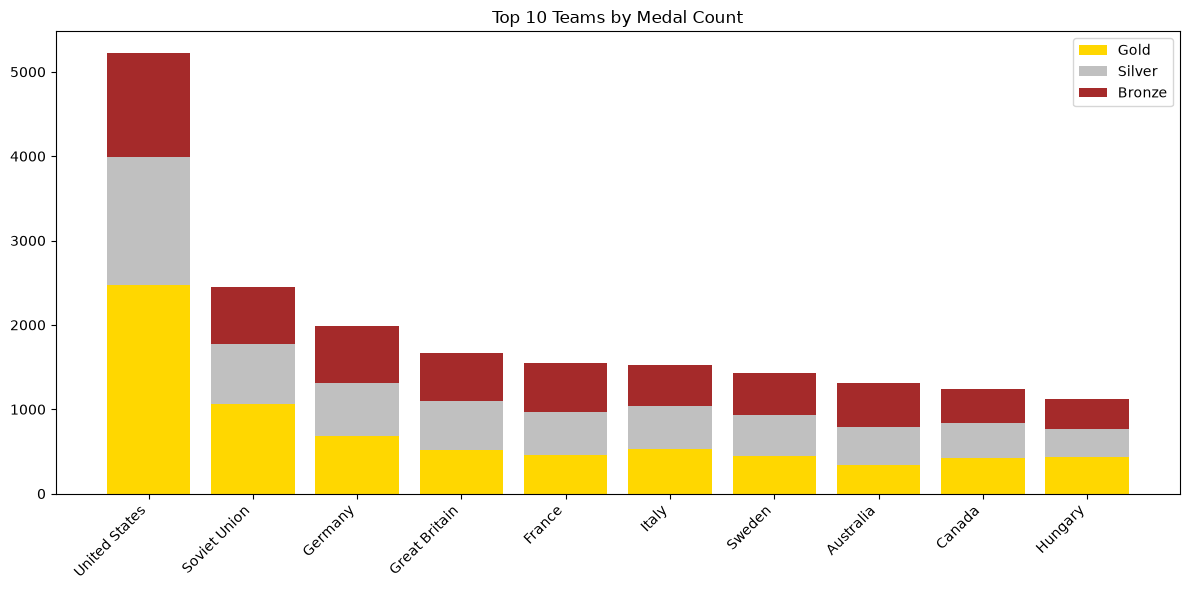

In [5]:
medals = df.groupby(["Team", "Medal"]).size().unstack(fill_value=0)
# size() counts rows in each group
# unstack() makes multi-index-series into DataFrame, inner index 'Medal' becomes columns

top10 = medals.sum(axis=1).nlargest(10)
medals_top10 = medals.loc[top10.index]

fig, ax = plt.subplots(figsize=(12,6))

ax.bar(medals_top10.index, medals_top10["Gold"], color="gold", label="Gold")

ax.bar(medals_top10.index, medals_top10["Silver"],
       bottom=medals_top10["Gold"], color="silver", label="Silver")

ax.bar(medals_top10.index, medals_top10["Bronze"],
       bottom=medals_top10["Gold"] + medals_top10["Silver"],
       color="brown", label="Bronze")

ax.legend()
plt.xticks(rotation=45, ha="right") # ha='right' means the the tick will be at the right edge of the text
plt.title("Top 10 Teams by Medal Count")
plt.tight_layout()
plt.show()

## Histograms

Histograms show the distribution of values within a variable

In [6]:
year_2016 = df[df['Year'] == 2016]

men_rowing = year_2016[
    (year_2016['Sex'] == 'M') & 
    (year_2016['Sport'] == 'Rowing') &
    (year_2016['Medal'].notna())
    ]

men_gymnastics = year_2016[
    (year_2016['Sex'] == 'M') & 
    (year_2016['Sport'] == 'Gymnastics') &
    (year_2016['Medal'].notna())
    ]

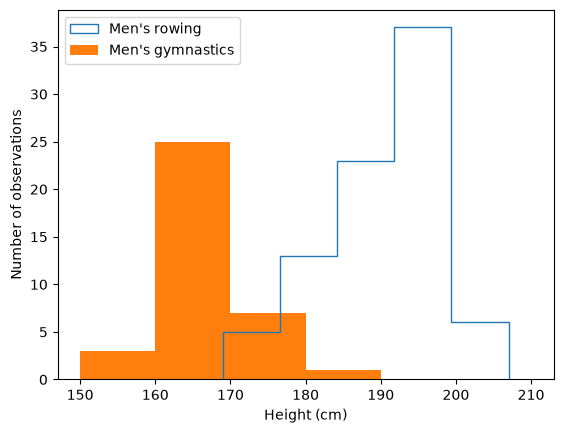

In [7]:
fig, ax = plt.subplots()
ax.hist(men_rowing['Height'], label="Men's rowing", 
        bins=5, histtype="step" #creates transparency
        ) #default bins are 10
ax.hist(men_gymnastics['Height'], label="Men's gymnastics", 
        bins=[150, 160, 170, 180, 190, 200, 210]) #here we set the boundaries between the bins
ax.set_xlabel('Height (cm)')
ax.set_ylabel('Number of observations')
ax.legend()

## Statistical plotting
Adding error bars to bar charts that summarize the distribution of the data in a number like the standard deviation

Text(0, 0.5, 'Height (cm)')

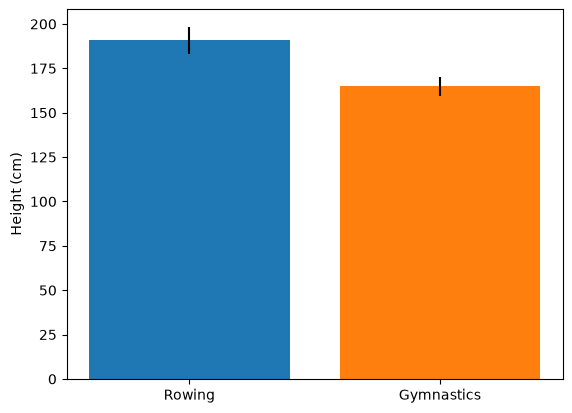

In [8]:
fig, ax = plt.subplots()

ax.bar("Rowing", 
       men_rowing['Height'].mean(),
       yerr=men_rowing['Height'].std())

ax.bar('Gymnastics',
       men_gymnastics['Height'].mean(),
       yerr=men_gymnastics['Height'].std())
ax.set_ylabel('Height (cm)')

The height of the bars show the mean values, and the error bar show the standarddeviation, which is pretty small here.

We can also add error bars to a line plot.

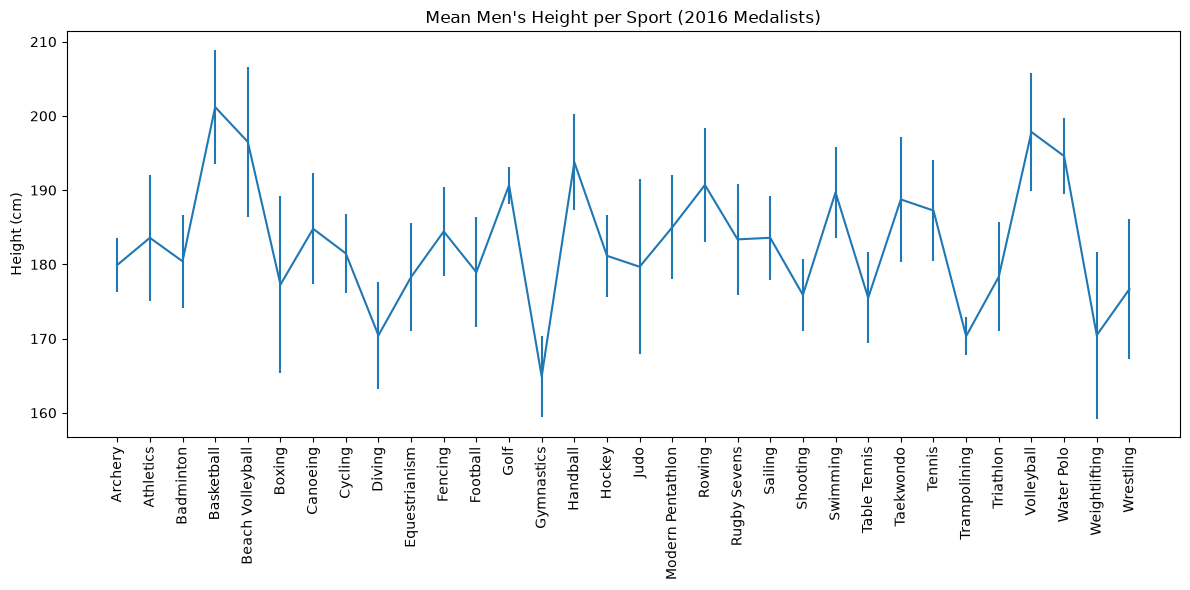

In [9]:

df_2016 = df[
    (df["Year"] == 2016) &
      (df['Sex'] == 'M') & 
      df["Medal"].notna()
    ]

height_stats = df_2016.groupby("Sport")["Height"].agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(12,6))

ax.errorbar(
    height_stats.index,
    height_stats['mean'],
    yerr=height_stats["std"]
)

ax.set_ylabel("Height (cm)")
ax.set_title("Mean Men's Height per Sport (2016 Medalists)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Boxplots is another statistical visualizations

Text(0, 0.5, 'Height (cm)')

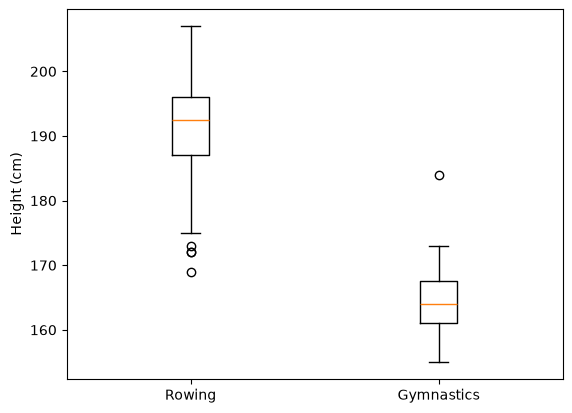

In [10]:
fig, ax = plt.subplots()
ax.boxplot([men_rowing['Height'], men_gymnastics['Height']])
ax.set_xticklabels(["Rowing", "Gymnastics"])
ax.set_ylabel("Height (cm)")

The red line shows the median height. The edges of the box indicate the IQR-range. The whiskers at the ends of the thin bars indicate one and a half times the size of the inter-quartile range beyond the 75th and 25th percentiles. This should encompass rougly 99 percent of the distribution if the data is Gaussian or normal.Points that appear beyond the whiskers are outliers. That means that they ave values larger or smaller than what you would expect for 99 percent of the data in a Gaussian or normal distribution.

## Scatterplot

Good for comparing two different variables 

fig, ax = plt.subplots()
ax.scatter(climate_change['co2], climate_change['relative_temp])
ax.set_xlabel('CO2 (ppm))
ax.set_ylabel('Relative temperature (Celsius"))

customizing scatter plot

eighties = climate_change["  " : "  "]
nineties
fig, ax = plt.subplots()
ax.scatter(eighties['co2'], eighties['relative_temp"], color='red', label='eighties)
ax.scatter(ninties['co2]...)




color can be used to compare 2 period for example, or to encode a third variable - providing additional information about the comparison

do this by c= 
very cool with for example time

changing plot style

In [11]:
plt.style.use('ggplot')
plt.style.use('bmh')
plt.style.use('seaborn-colorblind') #seaborn is based on matplotlib

OSError: 'seaborn-colorblind' is not a valid package style, path of style file, URL of style file, or library style name (library styles are listed in `style.available`)

if you want to go back you have to do the following

In [ ]:
plt.style.use('default')

think about how the people you want to share with

if color is important, consider choosing colorblind-friendly options
    'seaborn-colorblind'
    -tableau-colorblind10'

for printing in black and white: 'grayscale'


### Saving the figure to file

In [ ]:
fig.savefig('gold_medals.png') #lossless compression

#jpg , quality=50 # good on website. 
#lossy compression. less diskspace and less bandwidth

# svg - can be edited by advanced graphics. dpi=300. higher->denser


### Size

In [ ]:
fig.set_size_inches([5,3])

widhth, height


### Automating figures from data

Let's create a function to automatically plot data. We can create visualizations that ADAPT to the data provided.

/tmp/ipykernel_9331/3590265897.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(sports, rotation=90)


[Text(0, 0, 'Basketball'),
 Text(1, 0, 'Judo'),
 Text(2, 0, 'Football'),
 Text(3, 0, 'Tug-Of-War'),
 Text(4, 0, 'Speed Skating'),
 Text(5, 0, 'Cross Country Skiing'),
 Text(6, 0, 'Athletics'),
 Text(7, 0, 'Ice Hockey'),
 Text(8, 0, 'Swimming'),
 Text(9, 0, 'Badminton')]

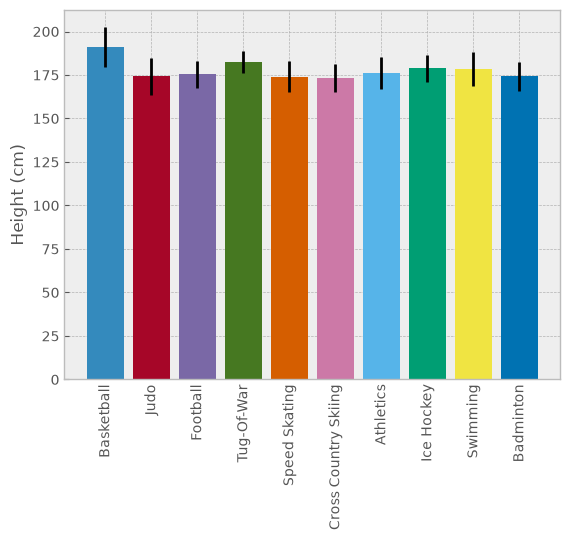

In [12]:
fig, ax = plt.subplots()

sports = df['Sport'].unique()[:10]

for sport in sports:
    sport_df = df[df['Sport'] == sport]
    ax.bar(sport, sport_df['Height'].mean(),
    yerr=sport_df['Height'].std())
ax.set_ylabel('Height (cm)')
ax.set_xticklabels(sports, rotation=90)
